In [228]:
import os
import re
import mne
import json
import pickle
import pyprep
import pathlib

import numpy as np
import pandas as pd
from mne.preprocessing import annotate_muscle_zscore
from mne_icalabel.label_components import label_components

In [229]:
raw_dataset = None
RAW_DATASET_NAME = pathlib.Path('data/raw_dataset.pkl')
EPOCH_DATASET_NAME = pathlib.Path('data/epoch_dataset.pkl')

def write_raw_dataset(raw_dataset: dict, path: pathlib.Path):
    with open(path, 'wb') as f:
        pickle.dump(raw_dataset, f)

def read_raw_dataset(path: pathlib.Path):
    data = None
    with open(path, 'rb') as f:
        data = pickle.load(f)
    return data

# Preprocessing

In this file we will perform:

- Preprocessing
  - High/Low/Band-Pass filters
  - Artifact removal
  - Bad electrode interpollation
- Annotation
- Epoching

Which will result in a ready-to-use dataset for further analysis and predictions.

## Data loading

In this first step, we read all the sessions from all the subjects and create a minimally filtered complete dataset. Only frequency filters have been applied to the data at this stage.

## Preprocessing - Filter and removing bad channels

In [230]:
INPUT_DIR = pathlib.Path("data/raw")
OUTPUT_DIR = pathlib.Path("data/preprocessed")
os.makedirs(OUTPUT_DIR, exist_ok=True)

def filter_eeg_before_artifact_removal(raw):
    raw.filter(l_freq=1.0, h_freq=None)
    raw.notch_filter(freqs=[50])
    return raw

def filter_eeg_after_artifact_removal(raw):
    raw.filter(l_freq=None, h_freq=45.)
    return raw

def artifact_removal(raw):
    raw_hipass = raw.copy()

    ica = mne.preprocessing.ICA(n_components=.99, method='picard')
    ica.fit(raw_hipass)

    # todo check what this does
    labels = label_components(raw_hipass, ica, method='iclabel')

    exclude = [
        i for i, (label, prob) in enumerate(zip(labels['labels'], labels['y_pred_proba']))
        if label not in ('brain', 'other') and prob > 0.8
    ]
    ica.exclude = exclude
    print("Excluding ICA components:", exclude, [labels['labels'][i] for i in exclude])

    ica.apply(raw)

    annot_muscle, scores_muscle = annotate_muscle_zscore(
        raw, ch_type='eeg', threshold=4, min_length_good=0.2,
        filter_freq=(110, 140)
    )
    raw.set_annotations(raw.annotations + annot_muscle)
    return raw

def interpolate_bad_channels(raw):
    nc = pyprep.NoisyChannels(raw)
    nc.find_all_bads(ransac=True)
    bad_channels = nc.get_bads()
    print(f'Bad channels: {bad_channels}')
    raw.info['bads'] = bad_channels
    raw.interpolate_bads(reset_bads=True)
    return raw

def read_raw_datasets_for_subject(dirname):
    pat = re.compile(r'_(\d{8}_\d{6})\.csv$')
    ts = sorted({m.group(1) for f in pathlib.Path(dirname).glob('*.csv') if (m := pat.search(f.name))})
    dataset = {}

    for i, t in enumerate(ts):
        eeg_csv = pd.read_csv(dirname / f'eeg_Experiment.VIBE.EEG_{t}.csv')
        eeg_metadata = ""
        gaze_csv = pd.read_csv(dirname / f'gaze_Experiment.VIBE.ViveOpenXR_Gaze_{t}.csv')
        gaze_metadata = ""
        markers = pd.read_json(dirname / f'markers_{t}.jsonl', lines=True)
        print(dirname / f'markers_{t}.jsonl')
        markers_payload = pd.json_normalize(markers['Payload'])
        markers_experimentconfig = pd.json_normalize(markers['ExperimentConfig'])
        markers_headtracking = pd.json_normalize(markers['HeadTracking'])
        markers = markers.drop(columns=["Payload", "ExperimentConfig", "HeadTracking"]).join(markers_payload).join(markers_experimentconfig).join(markers_headtracking)

        with open(dirname / f'eeg_Experiment.VIBE.EEG_{t}_metadata.txt', 'r') as f:
            eeg_metadata = f.read()
        with open(dirname / f'gaze_Experiment.VIBE.ViveOpenXR_Gaze_{t}_metadata.txt', 'r') as f:
            gaze_metadata = f.read()

        # load frequency from metadata
        match = re.search(r'Info:\s*(\{.*\})', eeg_metadata, re.DOTALL)
        if not match:
            raise ValueError("Info block not found in file")
        sfreq = json.loads(match.group(1))['sfreq']

        eeg_csv_useful_columns = eeg_csv.drop(['timestamp', 'X1', 'X2', 'X3', 'TRG'], axis=1)
        eeg_info = mne.create_info(ch_names=eeg_csv_useful_columns.columns.to_list(), sfreq=sfreq, ch_types='eeg')
        eeg = mne.io.RawArray(eeg_csv_useful_columns.to_numpy().T * 1e-6, eeg_info)
        eeg.rename_channels({"T3": "T7", "T4": "T8", "T5": "P7", "T6": "P8"})
        eeg.set_montage(mne.channels.make_standard_montage('standard_1020'), on_missing="ignore")

        eeg_filtered = filter_eeg_before_artifact_removal(eeg.copy())
        eeg_noise_removed = interpolate_bad_channels(eeg_filtered.copy())
        eeg_artifact_removed = artifact_removal(eeg_noise_removed.copy())
        eeg_clean = filter_eeg_after_artifact_removal(eeg_artifact_removed.copy())

        dataset[f'session_{i+1}'] = {
            'eeg': eeg_clean,
            'eeg_raw': eeg,
            'eeg_filtered': eeg_filtered,
            'eeg_noise_removed': eeg_noise_removed,
            'eeg_artifact_removed': eeg_artifact_removed,
            'ts': eeg_csv['timestamp'].to_numpy(),
            'eeg_metadata': eeg_metadata,
            'gaze': gaze_csv,
            'gaze_metadata': gaze_metadata,
            'markers': markers,
        }

        dataset[f'session_{i+1}']['markers'].timestamp -= dataset[f'session_{i+1}']['ts'][0]


    return dataset

def read_all_raw(ignored_subject_ids: list[str] = []):
    datasets = {}
    dirs = [f for f in os.listdir(INPUT_DIR) if os.path.isdir(INPUT_DIR / f) and f not in ignored_subject_ids]

    for dir in dirs:
        datasets[dir] = read_raw_datasets_for_subject(INPUT_DIR / dir)

    return datasets

RECOMPUTE_RAW_DATASET = False
if RECOMPUTE_RAW_DATASET or not RAW_DATASET_NAME.exists():
    raw_dataset = read_all_raw()
    write_raw_dataset(raw_dataset, RAW_DATASET_NAME)
elif raw_dataset is None:
    raw_dataset = read_raw_dataset(RAW_DATASET_NAME)

## Creating epochs

The EEG data is split into epochs all centered around the different markers. Additionally, all events are annotated on the timeline.

In [246]:
T_MIN = -1.0
T_MAX = 1.0
EVENT_IDS = {
    'BlinkLog_L': 0,
    'BlinkLog_R': 1,
    'PinchLog': 2,
    'ExperimentManagerLog': 3,
    'GazeLog': 4,
    'ExperimentLog': 5
}

def annotate_and_epoch_eeg():
    raw_dataset = read_raw_dataset(RAW_DATASET_NAME)
    ds = {}

    for subject in raw_dataset:
        sessions_dataset = {}

        for session in raw_dataset[subject]:
            m = raw_dataset[subject][session]['markers']
            m = m.sort_values('timestamp').reset_index(drop=True)

            # -----------------------------
            # drop pinch double activations
            is_pinch = m['EventType'] == 'PinchLog'
            pinch_df = m[is_pinch].copy()

            # group events closer than .3s
            gap = pinch_df['timestamp'].diff()
            new_group = (gap > 0.3) | gap.isna()
            pinch_df['group'] = new_group.cumsum()

            # keep only the first occurrence per group
            pinch_first = pinch_df.drop_duplicates(subset='group', keep='first').drop(columns='group')
            m = pd.concat([m[~is_pinch], pinch_first]).sort_values('timestamp').reset_index(drop=True)

            # -----------------
            # build annotations
            # separate blink starts and ends
            blinks_start = []
            blinks_duration = []
            blinks_description = []
            for eye in ['LEFT', 'RIGHT']:
                blinks = m[(m.EventType=='BlinkLog') & (m.Eye==eye)]
                for i in range(len(blinks)):
                    b = blinks.iloc[i]
                    if b.State=='BLINK_START':
                        blinks_start.append(b.timestamp)
                        if (i+1) < len(blinks) and blinks.iloc[i+1].State=='BLINK_END':
                            blinks_duration.append(blinks.iloc[i+1].timestamp - b.timestamp)
                        else:
                            blinks_duration.append(0)
                        blinks_description.append(f'Blink/{eye}')

            blink_annotations = mne.Annotations(
                onset=blinks_start,
                duration=blinks_duration,
                description=blinks_description,
            )

            # pinch events
            pinches = m[m['EventType'].isin(['PinchLog'])]
            pinch_annotations = mne.Annotations(
                onset=pinches['timestamp'].values,
                duration=[0.0] * len(pinches),
                description=pinches['PinchType'].values,
            )

            raw_dataset[subject][session]['eeg'].set_annotations(raw_dataset[subject][session]['eeg'].annotations + blink_annotations + pinch_annotations)

            # -------------------
            # events for epoching
            m['sample'] = (m.timestamp * 300).round().astype(int) + raw_dataset['subject_27']['session_1']['eeg'].first_samp
            m.loc[(m.EventType == 'BlinkLog') & (m.Eye == 'LEFT'), 'EventType'] = 'BlinkLog_L'
            m.loc[(m.EventType == 'BlinkLog') & (m.Eye == 'RIGHT'), 'EventType'] = 'BlinkLog_R'

            events = np.array([
                m['sample'].to_list(),
                [0] * m['sample'].shape[0],
                [EVENT_IDS[e] for e in m['EventType']],
            ]).T.astype(int)

            # increment the duplicates' sample index by 1
            unique_rows, counts = np.unique(events[:, 0], return_counts=True)
            duplicated_values = unique_rows[counts > 1]
            while len(duplicated_values > 0):
                events_df = pd.DataFrame(events)
                offset = events_df.groupby(0).cumcount()
                events_df[0] = events_df[0] + offset
                events = events_df.to_numpy()
                unique_rows, counts = np.unique(events[:, 0], return_counts=True)
                duplicated_values = unique_rows[counts > 1]

            events = events.astype(int)
            epochs = mne.Epochs(raw_dataset[subject][session]['eeg'], events, event_id=EVENT_IDS, metadata=m, tmin=T_MIN, tmax=T_MAX, preload=True)
            sessions_dataset[session] = epochs
        ds[subject] = sessions_dataset

    write_raw_dataset(raw_dataset, ANNOTATED_DATASET_NAME)
    write_raw_dataset(ds, EPOCH_DATASET_NAME)
    return ds, raw_dataset

epoched_dataset, annotated_dataset = annotate_and_epoch_eeg()

Adding metadata with 52 columns
1502 matching events found
Setting baseline interval to [-1.0, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 1502 events and 601 original time points ...
340 bad epochs dropped
Adding metadata with 52 columns
915 matching events found
Setting baseline interval to [-1.0, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 915 events and 601 original time points ...
128 bad epochs dropped
Adding metadata with 52 columns
2204 matching events found
Setting baseline interval to [-1.0, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 2204 events and 601 original time points ...
424 bad epochs dropped
Adding metadata with 52 columns
1463 matching events found
Setting baseline interval to [-1.0, 0.0] s
Applying baseline correction (mode: mean)
0 projection items activated
Usin

## Timing sanity check

As a quick sanity check to the timing, the blink value can be used. Blinks have an expected duration of .2 to .4s, the peak activation in the frontal channels is to be expected in the midway of the blink.

The following diagram cleanly shows the start of the measured blink to be right around the rising edge of the frontal EEG channels.

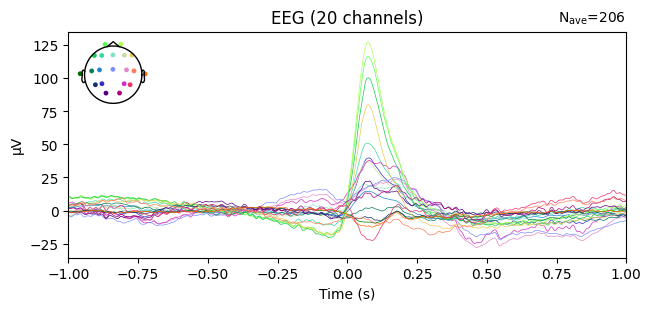

In [253]:
_ = epoched_dataset['subject_27']['session_1']['BlinkLog_L']['State == "BLINK_START"'].average().plot()